Proceso completado. Se ha generado 'iris_con_clusters.csv' con las etiquetas.
   sepal_length  sepal_width  petal_length  petal_width species  cluster
0           5.1          3.5           1.4          0.2  setosa        1
1           4.9          3.0           1.4          0.2  setosa        1
2           4.7          3.2           1.3          0.2  setosa        1
3           4.6          3.1           1.5          0.2  setosa        1
4           5.0          3.6           1.4          0.2  setosa        1


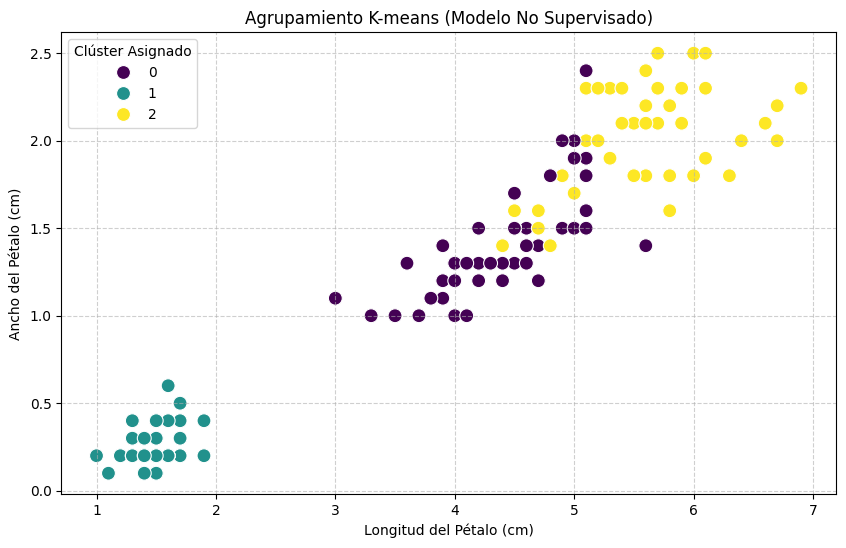

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# 1. Cargar el dataset
df = pd.read_csv('Iris-1.csv')

# 2. Seleccionar solo las variables de entrada (X)
# Eliminamos la columna 'species' porque es un modelo no supervisado
X = df.drop(columns=['species'])

# 3. Estandarizar los datos
# K-means se basa en distancias, por lo que es vital que todas las
# variables estén en la misma escala.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Configurar y entrenar el modelo K-means
# Definimos k=3 clústeres
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

# 5. Agregar los resultados al DataFrame original
df['cluster'] = clusters

# 6. Visualización de los resultados
# Graficamos basándonos en los pétalos para ver la separación
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x='petal_length',
    y='petal_width',
    hue='cluster',
    palette='viridis',
    s=100
)
plt.title('Agrupamiento K-means (Modelo No Supervisado)')
plt.xlabel('Longitud del Pétalo (cm)')
plt.ylabel('Ancho del Pétalo (cm)')
plt.legend(title='Clúster Asignado')
plt.grid(True, linestyle='--', alpha=0.6)

# Guardar la imagen y el resultado
plt.savefig('resultado_clusters.png')
df.to_csv('iris_con_clusters.csv', index=False)

print("Proceso completado. Se ha generado 'iris_con_clusters.csv' con las etiquetas.")
print(df.head())

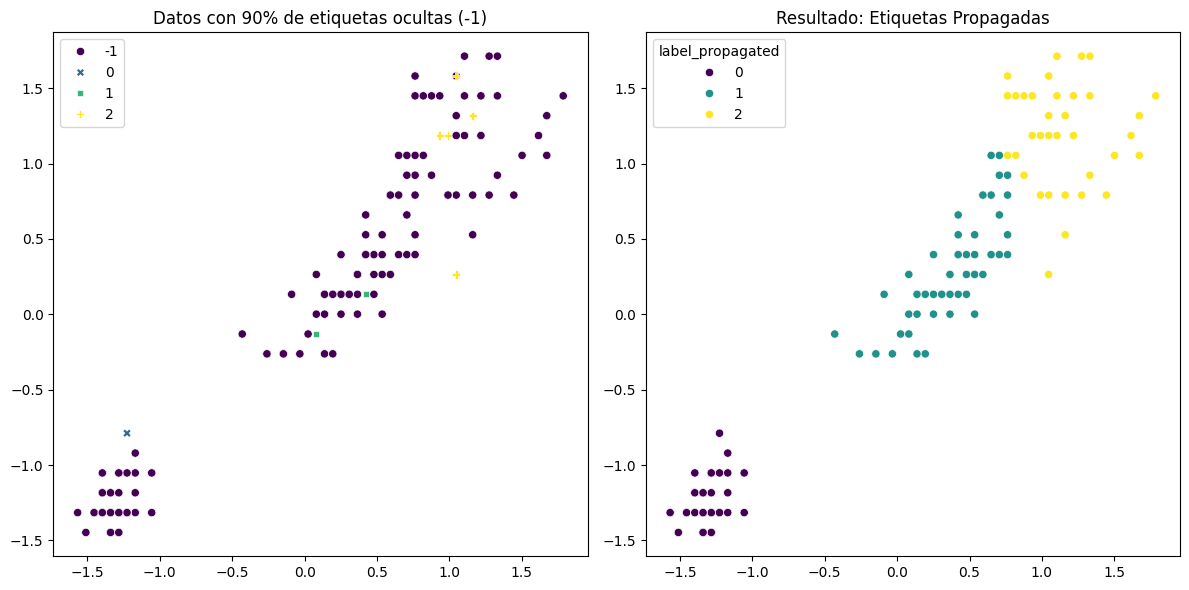

Precisión del modelo usando solo el 10% de etiquetas: 90.67%


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.semi_supervised import LabelPropagation
from sklearn.preprocessing import StandardScaler

# 1. Cargar el dataset
df = pd.read_csv('Iris-1.csv')

# 2. Preparar los datos
X = df.drop(columns=['species'])
y_true = df['species'].astype('category').cat.codes # Convertimos nombres a números (0, 1, 2)

# 3. Simular escenario semi-supervisado
# Vamos a ocultar el 90% de las etiquetas.
# En scikit-learn, las etiquetas faltantes se marcan con -1.
rng = np.random.RandomState(42)
random_unlabeled_points = rng.rand(len(y_true)) < 0.9
y_masked = np.copy(y_true)
y_masked[random_unlabeled_points] = -1

# 4. Estandarizar (igual que en tu ejemplo)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 5. Configurar y entrenar el modelo Label Propagation
# Este modelo "contagia" la etiqueta de un punto a sus vecinos más cercanos
lp_model = LabelPropagation(kernel='knn', n_neighbors=7)
lp_model.fit(X_scaled, y_masked)

# 6. Obtener las etiquetas predichas (las que el modelo propagó)
df['label_propagated'] = lp_model.transduction_

# 7. Visualización
plt.figure(figsize=(12, 6))

# Subplot 1: Lo que el modelo veía (muchos puntos sin etiqueta -1)
plt.subplot(1, 2, 1)
sns.scatterplot(x=X_scaled[:, 2], y=X_scaled[:, 3], hue=y_masked, palette='viridis', style=y_masked)
plt.title('Datos con 90% de etiquetas ocultas (-1)')

# Subplot 2: Resultado después de la propagación
plt.subplot(1, 2, 2)
sns.scatterplot(x=X_scaled[:, 2], y=X_scaled[:, 3], hue=df['label_propagated'], palette='viridis')
plt.title('Resultado: Etiquetas Propagadas')

plt.tight_layout()
plt.show()

print(f"Precisión del modelo usando solo el 10% de etiquetas: {lp_model.score(X_scaled, y_true):.2%}")